# 03 — Drug endpoints (checklist 2.2–2.5)

Validate the three drug endpoints of the **validated untreated 7D Plant–Kim / Canavier** model, plus the exact 5D TTX reduction sanity check.

- Canonical endpoint simulations: 7D via `src/plant_kim_model.py` (unchanged)
- Exact TTX reduction only: `src/plant_kim_ttx_5d.py`
- Solver: PyDSTool **VODE only**
- Interventions: complete TTX (`g_I=0`), complete ouabain (`I_ep=0`), combined (`g_I=0`, `I_ep=0`)
- Out of scope: parameter sweeps, AUTO, SciPy ODE solvers, checklist edits, model retuning


## 1. Purpose and scope

Test Hypotheses 1–3 at the hard endpoints only:

1. TTX → loss of fast spikes → slow-wave oscillation
2. Ouabain → regular beating / more regular spike activity
3. TTX + ouabain → suppression of slow oscillation → stable equilibrium

Also verify that 7D at `g_I=0` and the exact 5D reduction produce the same common dynamics.

If an endpoint contradicts the expected qualitative behaviour: **stop and report** — do not retune parameters or the solver.


## 2. Imports and environment confirmation


In [1]:
import sys
from copy import deepcopy
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import csv

import numpy as np
import matplotlib.pyplot as plt

from src.plant_kim_model import (
    BASELINE_PARS,
    STATE_VARS,
    DEFAULT_ALGPARAMS,
    DEFAULT_V0,
    steady_state_ics,
    build_vode_system,
    simulate,
)
from src.plant_kim_ttx_5d import (
    STATE_VARS_5D,
    default_pars_5d,
    steady_state_ics_5d,
    build_vode_system_5d,
)

FIGDIR = REPO_ROOT / 'outputs' / 'figures' / 'drug_endpoints'
FIGDIR.mkdir(parents=True, exist_ok=True)

print('executable:', sys.executable)
print('version:', sys.version.split()[0])
assert '.venv' in sys.executable.replace('\\', '/'), 'Use the project .venv interpreter / pydstool kernel'
print('FIGDIR:', FIGDIR)
print('DEFAULT_ALGPARAMS:', DEFAULT_ALGPARAMS)
print('baseline g_I =', BASELINE_PARS['g_I'], 'I_ep =', BASELINE_PARS['I_ep'])


executable: /Users/calvinlai/Desktop/MATH3888/.venv/bin/python
version: 3.9.20
FIGDIR: /Users/calvinlai/Desktop/MATH3888/outputs/figures/drug_endpoints
DEFAULT_ALGPARAMS: {'rtol': 1e-06, 'atol': 1e-08, 'stiff': True, 'init_step': 0.1, 'max_step': 1.0}
baseline g_I = 4.0 I_ep = -0.22


## 3. Load validated canonical 7D model

Import-only reuse. Parameter overrides always start from `dict(BASELINE_PARS)` because `pars=` fully replaces rather than merges.


In [2]:
ICS_7D = steady_state_ics(DEFAULT_V0)
ICS_5D = steady_state_ics_5d(DEFAULT_V0)
print('DEFAULT_V0 =', DEFAULT_V0)
print('7D ICs:', {k: round(v, 6) for k, v in ICS_7D.items()})
print('5D ICs:', {k: round(v, 6) for k, v in ICS_5D.items()})
assert all(np.isclose(ICS_7D[k], ICS_5D[k]) for k in STATE_VARS_5D)


DEFAULT_V0 = -50.0
7D ICs: {'V': -50.0, 'X_K': 0.046642, 'X_A': 0.401312, 'Y_A': 0.5, 'X_P': 0.109097, 'X_I': 0.017488, 'Y_I': 0.902731}
5D ICs: {'V': -50.0, 'X_K': 0.046642, 'X_A': 0.401312, 'Y_A': 0.5, 'X_P': 0.109097}


## 4. Common simulation and post-transient analysis helpers


In [3]:
DT = 0.5  # ms sample
SPIKE_THR = -20.0  # mV upward-crossing threshold
BURST_GAP = 1500.0  # ms: ISI > this starts a new burst
EQ_V_RANGE = 0.5  # mV: late-window range below this → equilibrium candidate
EQ_MEAN_DVDT = 1e-3  # mV/ms
GATE_VARS = [v for v in STATE_VARS if v != 'V']


def make_drug_pars(g_I=None, I_ep=None):
    """Copy baseline pars and optionally override drug endpoints."""
    pars = dict(BASELINE_PARS)
    if g_I is not None:
        pars['g_I'] = float(g_I)
    if I_ep is not None:
        pars['I_ep'] = float(I_ep)
    return pars


def assert_pars_match_baseline_except(pars, changed):
    for k, v0 in BASELINE_PARS.items():
        if k in changed:
            continue
        assert np.isclose(pars[k], v0), f'{k} changed unexpectedly: {pars[k]} vs {v0}'


def pts_to_data(pts, state_vars):
    return {k: np.asarray(pts[k], dtype=float) for k in ['t', *state_vars]}


def run_7d(name, pars, t_end, ics=None, trajname=None):
    ics = ICS_7D if ics is None else ics
    ode = build_vode_system(pars=pars, ics=ics, name='PK7D_' + name)
    print(
        f'Computing 7D {name}: g_I={ode.pars["g_I"]}, I_ep={ode.pars["I_ep"]}, '
        f'T_END={t_end} ms ...',
        flush=True,
    )
    pts = simulate(ode, tdata=[0.0, t_end], dt=DT, trajname=trajname or name)
    data = pts_to_data(pts, STATE_VARS)
    print(
        f'  done: V in [{data["V"].min():.3g}, {data["V"].max():.3g}] mV',
        flush=True,
    )
    return ode, data


def run_5d(name, pars_5d, t_end, ics=None, trajname=None):
    ics = ICS_5D if ics is None else ics
    ode = build_vode_system_5d(pars=pars_5d, ics=ics, name='PK5D_' + name)
    print(
        f'Computing 5D {name}: I_ep={ode.pars["I_ep"]}, T_END={t_end} ms ...',
        flush=True,
    )
    pts = simulate(ode, tdata=[0.0, t_end], dt=DT, trajname=trajname or name)
    data = pts_to_data(pts, STATE_VARS_5D)
    print(
        f'  done: V in [{data["V"].min():.3g}, {data["V"].max():.3g}] mV',
        flush=True,
    )
    return ode, data


def group_bursts(tspike, gap=BURST_GAP):
    if len(tspike) == 0:
        return []
    groups = [[tspike[0]]]
    for i in range(1, len(tspike)):
        if tspike[i] - tspike[i - 1] > gap:
            groups.append([tspike[i]])
        else:
            groups[-1].append(tspike[i])
    return groups


def estimate_slow_period_ms(t, V):
    """Estimate slow-wave period from successive local maxima of lightly smoothed V."""
    if len(V) < 20:
        return float('nan')
    # Moving average ~50 ms at DT=0.5
    w = max(3, int(round(50.0 / DT)))
    if w % 2 == 0:
        w += 1
    kernel = np.ones(w) / w
    Vs = np.convolve(V, kernel, mode='same')
    # Require prominence relative to half-range
    half = 0.25 * (Vs.max() - Vs.min())
    peaks = []
    for i in range(1, len(Vs) - 1):
        if Vs[i] >= Vs[i - 1] and Vs[i] > Vs[i + 1] and Vs[i] > (Vs.mean() + 0.1 * half):
            if not peaks or (t[i] - peaks[-1]) > 500.0:
                peaks.append(t[i])
    if len(peaks) < 2:
        return float('nan')
    return float(np.median(np.diff(peaks)))


def check_finite_and_gates(data, state_vars):
    for k in ['t', *state_vars]:
        arr = data[k]
        if not np.all(np.isfinite(arr)):
            return False, f'non-finite values in {k}'
    for g in state_vars:
        if g == 'V':
            continue
        gmin, gmax = float(data[g].min()), float(data[g].max())
        if gmin < -0.05 or gmax > 1.05:
            return False, f'gate {g} out of sensible range [{gmin:.3g}, {gmax:.3g}]'
    return True, 'ok'


def classify_endpoint(data, t_cut, late_window_ms=None):
    """Post-transient regime classification (ordered rules from the plan)."""
    t = data['t']
    V = data['V']
    ok, msg = check_finite_and_gates(data, [k for k in data if k != 't'])
    if not ok:
        return {
            'regime': 'FAIL',
            'detail': msg,
            'V_min': float('nan'),
            'V_max': float('nan'),
            'period_s': float('nan'),
            'n_spikes': 0,
            'spikes_per_cycle': float('nan'),
            'aps_absent': None,
        }

    mask = t >= t_cut
    t2, V2 = t[mask], V[mask]
    if late_window_ms is not None:
        t_late0 = t2[-1] - late_window_ms
        late = t2 >= t_late0
        t_late, V_late = t2[late], V2[late]
    else:
        t_late, V_late = t2, V2

    V_min = float(V2.min())
    V_max = float(V2.max())
    V_range_late = float(V_late.max() - V_late.min())
    dVdt = np.diff(V_late) / np.diff(t_late) if len(V_late) > 1 else np.array([0.0])
    mean_abs_dVdt = float(np.mean(np.abs(dVdt)))

    cross = np.where((V2[:-1] <= SPIKE_THR) & (V2[1:] > SPIKE_THR))[0]
    tspike = t2[cross]
    groups = group_bursts(tspike)
    sizes = [len(g) for g in groups]
    onsets = [g[0] for g in groups]
    periods_spike = np.diff(onsets) if len(onsets) >= 2 else np.array([])

    aps_absent = len(tspike) == 0

    # 1) Equilibrium
    if V_range_late < EQ_V_RANGE and mean_abs_dVdt < EQ_MEAN_DVDT:
        return {
            'regime': 'equilibrium',
            'detail': f'late V range={V_range_late:.3g} mV, mean|dV/dt|={mean_abs_dVdt:.3g}',
            'V_min': float(V_late.min()),
            'V_max': float(V_late.max()),
            'period_s': float('nan'),
            'n_spikes': int(len(tspike)),
            'spikes_per_cycle': float('nan'),
            'aps_absent': aps_absent,
            'V_range_late': V_range_late,
            'mean_abs_dVdt': mean_abs_dVdt,
        }

    # 2) Spiking
    if len(tspike) >= 2:
        med_size = float(np.median(sizes)) if sizes else float('nan')
        # Clear inter-burst silence: at least one gap > BURST_GAP already used in grouping
        if len(groups) >= 2 and med_size >= 2:
            regime = 'bursting'
            period_ms = float(np.median(periods_spike)) if len(periods_spike) else float('nan')
            spc = med_size
        else:
            regime = 'regular_beating'
            isis = np.diff(tspike)
            period_ms = float(np.median(isis)) if len(isis) else float('nan')
            spc = 1.0
        return {
            'regime': regime,
            'detail': f'n_spikes={len(tspike)}, n_groups={len(groups)}, median_size={med_size}',
            'V_min': V_min,
            'V_max': V_max,
            'period_s': period_ms / 1000.0 if np.isfinite(period_ms) else float('nan'),
            'n_spikes': int(len(tspike)),
            'spikes_per_cycle': spc,
            'aps_absent': False,
            'V_range_late': V_range_late,
            'mean_abs_dVdt': mean_abs_dVdt,
        }

    # 3) Slow wave / oscillatory without APs
    if (V_max - V_min) >= EQ_V_RANGE:
        period_ms = estimate_slow_period_ms(t2, V2)
        return {
            'regime': 'slow_wave',
            'detail': f'V range={V_max - V_min:.3g} mV, n_spikes={len(tspike)}',
            'V_min': V_min,
            'V_max': V_max,
            'period_s': period_ms / 1000.0 if np.isfinite(period_ms) else float('nan'),
            'n_spikes': int(len(tspike)),
            'spikes_per_cycle': float('nan'),
            'aps_absent': aps_absent,
            'V_range_late': V_range_late,
            'mean_abs_dVdt': mean_abs_dVdt,
        }

    return {
        'regime': 'other',
        'detail': f'unclassified; V range={V_max - V_min:.3g}',
        'V_min': V_min,
        'V_max': V_max,
        'period_s': float('nan'),
        'n_spikes': int(len(tspike)),
        'spikes_per_cycle': float('nan'),
        'aps_absent': aps_absent,
        'V_range_late': V_range_late,
        'mean_abs_dVdt': mean_abs_dVdt,
    }


def plot_V_trace(data, title, fname, t_cut=None):
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(data['t'] / 1000.0, data['V'], lw=0.8, color='C0')
    if t_cut is not None:
        ax.axvline(t_cut / 1000.0, color='k', ls='--', lw=0.8, alpha=0.6)
    ax.set_xlabel('t (s)')
    ax.set_ylabel('V (mV)')
    ax.set_title(title)
    fig.tight_layout()
    out = FIGDIR / fname
    fig.savefig(out, dpi=150)
    plt.show()
    print('saved', out)
    return out


def metrics_row(intervention, g_I, I_ep, metrics):
    return {
        'intervention': intervention,
        'g_I': g_I,
        'I_ep': I_ep,
        'regime': metrics['regime'],
        'V_min': metrics['V_min'],
        'V_max': metrics['V_max'],
        'period_s': metrics['period_s'],
        'n_spikes': metrics['n_spikes'],
        'spikes_per_cycle': metrics['spikes_per_cycle'],
        'aps_absent': metrics['aps_absent'],
        'detail': metrics.get('detail', ''),
    }


## 5. Untreated reference (brief)

Short confirmation that the validated baseline still bursts; not a full re-audit.


In [4]:
T_END_REF = 40000.0
T_CUT_REF = 10000.0

pars_ref = make_drug_pars()
assert_pars_match_baseline_except(pars_ref, changed=())
ode_ref, data_ref = run_7d('untreated', pars_ref, T_END_REF)
met_ref = classify_endpoint(data_ref, T_CUT_REF)
print(met_ref)
assert met_ref['regime'] != 'FAIL'
summary_rows = [
    metrics_row('untreated', pars_ref['g_I'], pars_ref['I_ep'], met_ref)
]


Computing 7D untreated: g_I=4.0, I_ep=-0.22, T_END=40000.0 ms ...


  done: V in [-52, 27.7] mV


{'regime': 'bursting', 'detail': 'n_spikes=12, n_groups=3, median_size=4.0', 'V_min': -51.623350363172484, 'V_max': 27.487073908164597, 'period_s': 9.043472608681522, 'n_spikes': 12, 'spikes_per_cycle': 4.0, 'aps_absent': False, 'V_range_late': 79.11042427133708, 'mean_abs_dVdt': 0.06386228544192042}


## 6. TTX endpoint — canonical 7D (`g_I = 0`)

Expected (Hypothesis 1): loss of fast action potentials → slow membrane oscillation.


Computing 7D ttx: g_I=0.0, I_ep=-0.22, T_END=80000.0 ms ...


  done: V in [-52.5, -30.3] mV


{'regime': 'slow_wave', 'detail': 'V range=13.6 mV, n_spikes=0', 'V_min': -52.46262122387907, 'V_max': -38.89599816225635, 'period_s': 9.971012463765582, 'n_spikes': 0, 'spikes_per_cycle': nan, 'aps_absent': True, 'V_range_late': 13.566623061622721, 'mean_abs_dVdt': 0.0027165422317884003}


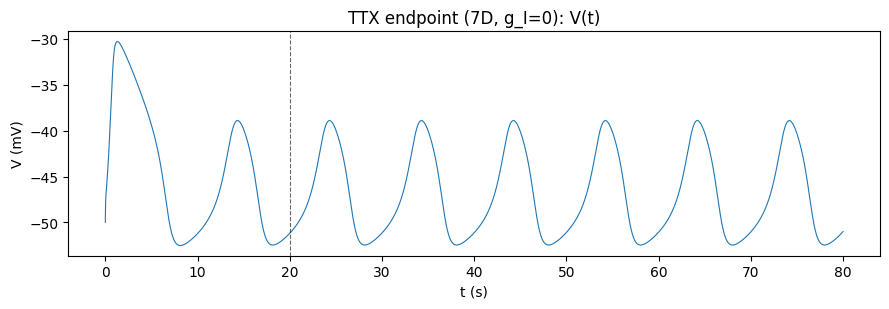

saved /Users/calvinlai/Desktop/MATH3888/outputs/figures/drug_endpoints/ttx_V_trace.png
TTX 7D: PASS (slow_wave, APs absent)


In [5]:
T_END_TTX = 80000.0
T_CUT_TTX = 20000.0

pars_ttx = make_drug_pars(g_I=0.0)
assert_pars_match_baseline_except(pars_ttx, changed=('g_I',))
assert pars_ttx['g_I'] == 0.0
assert np.isclose(pars_ttx['I_ep'], BASELINE_PARS['I_ep'])

ode_ttx, data_ttx = run_7d('ttx', pars_ttx, T_END_TTX)
assert ode_ttx.pars['g_I'] == 0.0
met_ttx = classify_endpoint(data_ttx, T_CUT_TTX)
print(met_ttx)
assert met_ttx['regime'] != 'FAIL', met_ttx

plot_V_trace(
    data_ttx,
    title='TTX endpoint (7D, g_I=0): V(t)',
    fname='ttx_V_trace.png',
    t_cut=T_CUT_TTX,
)
summary_rows.append(metrics_row('TTX', pars_ttx['g_I'], pars_ttx['I_ep'], met_ttx))

if met_ttx['regime'] != 'slow_wave' or not met_ttx['aps_absent']:
    raise RuntimeError(
        'TTX endpoint did not match Hypothesis 1 (expected slow_wave, APs absent). '
        f'Got regime={met_ttx["regime"]}, aps_absent={met_ttx["aps_absent"]}, detail={met_ttx["detail"]}'
    )
print('TTX 7D: PASS (slow_wave, APs absent)')


## 7. Exact TTX 5D reduction

At `g_I=0`, ODEs for $X_I$ and $Y_I$ are removed and the voltage equation drops $g_I X_I^3 Y_I(V_I-V)$. Persistent $g_T$ remains. Auxiliaries `alpha_m/beta_m/alpha_h/beta_h/S_I/Z_I/tau_X_I/tau_Y_I` are unnecessary.


In [6]:
pars_5d = default_pars_5d()
# Keep I_ep at untreated baseline for the TTX-only reduction check
assert np.isclose(pars_5d['I_ep'], BASELINE_PARS['I_ep'])
assert 'g_I' not in pars_5d

ode_ttx5, data_ttx5 = run_5d('ttx5d', pars_5d, T_END_TTX)
met_ttx5 = classify_endpoint(data_ttx5, T_CUT_TTX)
print('5D metrics:', met_ttx5)
assert met_ttx5['regime'] != 'FAIL'


Computing 5D ttx5d: I_ep=-0.22, T_END=80000.0 ms ...


  done: V in [-52.5, -30.3] mV


5D metrics: {'regime': 'slow_wave', 'detail': 'V range=13.6 mV, n_spikes=0', 'V_min': -52.46263078462258, 'V_max': -38.89594905822566, 'period_s': 9.971012463765575, 'n_spikes': 0, 'spikes_per_cycle': nan, 'aps_absent': True, 'V_range_late': 13.566681726396922, 'mean_abs_dVdt': 0.0027165592412895312}


## 8. TTX 7D vs 5D numerical sanity check

Identical common ICs, parameters (physical), VODE settings, time span, and sampling grid.


V     max_abs=2.005856e-03  rmse=5.929388e-04
X_K   max_abs=1.482114e-05  rmse=4.377566e-06
X_A   max_abs=3.982538e-05  rmse=1.165626e-05
Y_A   max_abs=1.147463e-04  rmse=2.725495e-05
X_P   max_abs=2.079216e-05  rmse=9.129472e-06
max_abs_err_all = 0.0020058555051249982
saved /Users/calvinlai/Desktop/MATH3888/outputs/figures/drug_endpoints/ttx_7d_vs_5d_errors.csv


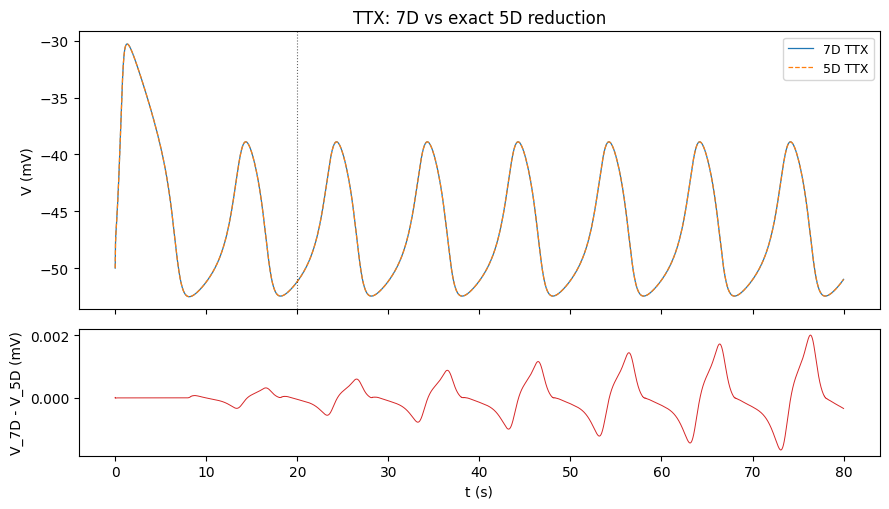

saved /Users/calvinlai/Desktop/MATH3888/outputs/figures/drug_endpoints/ttx_7d_vs_5d.png
7D vs 5D TTX: PASS (errors near numerical tolerance)


In [7]:
assert np.allclose(data_ttx['t'], data_ttx5['t'])

err_rows = []
max_abs_all = 0.0
for var in STATE_VARS_5D:
    d = data_ttx[var] - data_ttx5[var]
    max_abs = float(np.max(np.abs(d)))
    rmse = float(np.sqrt(np.mean(d ** 2)))
    max_abs_all = max(max_abs_all, max_abs)
    err_rows.append({'variable': var, 'max_abs': max_abs, 'rmse': rmse})
    print(f'{var:4s}  max_abs={max_abs:.6e}  rmse={rmse:.6e}')

print('max_abs_err_all =', max_abs_all)
err_csv = FIGDIR / 'ttx_7d_vs_5d_errors.csv'
with open(err_csv, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=['variable', 'max_abs', 'rmse'])
    writer.writeheader()
    writer.writerows(err_rows)
print('saved', err_csv)

fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True,
                         gridspec_kw={'height_ratios': [2.2, 1]})
axes[0].plot(data_ttx['t'] / 1000.0, data_ttx['V'], lw=0.9, label='7D TTX')
axes[0].plot(data_ttx5['t'] / 1000.0, data_ttx5['V'], lw=0.9, ls='--', label='5D TTX')
axes[0].axvline(T_CUT_TTX / 1000.0, color='k', ls=':', lw=0.8, alpha=0.6)
axes[0].set_ylabel('V (mV)')
axes[0].set_title('TTX: 7D vs exact 5D reduction')
axes[0].legend(loc='best', fontsize=9)
resid = data_ttx['V'] - data_ttx5['V']
axes[1].plot(data_ttx['t'] / 1000.0, resid, lw=0.7, color='C3')
axes[1].set_xlabel('t (s)')
axes[1].set_ylabel('V_7D - V_5D (mV)')
fig.tight_layout()
fig.savefig(FIGDIR / 'ttx_7d_vs_5d.png', dpi=150)
plt.show()
print('saved', FIGDIR / 'ttx_7d_vs_5d.png')

# Agreement should be near solver tolerance accumulation; flag gross mismatch.
if max_abs_all > 1e-2:
    raise RuntimeError(
        f'7D vs 5D TTX disagreement too large (max_abs_all={max_abs_all}). '
        'Treat as a reduction-implementation bug before interpreting science.'
    )
print('7D vs 5D TTX: PASS (errors near numerical tolerance)')


## 9. Ouabain endpoint — canonical 7D (`I_ep = 0`)

Expected (Hypothesis 2): bursting → regular beating / more regular spike activity.


Computing 7D ouabain: g_I=4.0, I_ep=0.0, T_END=60000.0 ms ...


  done: V in [-50, 27.7] mV


{'regime': 'regular_beating', 'detail': 'n_spikes=105, n_groups=1, median_size=105.0', 'V_min': -49.296060774221125, 'V_max': 26.60671833224597, 'period_s': 0.4492507487512485, 'n_spikes': 105, 'spikes_per_cycle': 1.0, 'aps_absent': False, 'V_range_late': 75.9027791064671, 'mean_abs_dVdt': 0.3529204829986971}


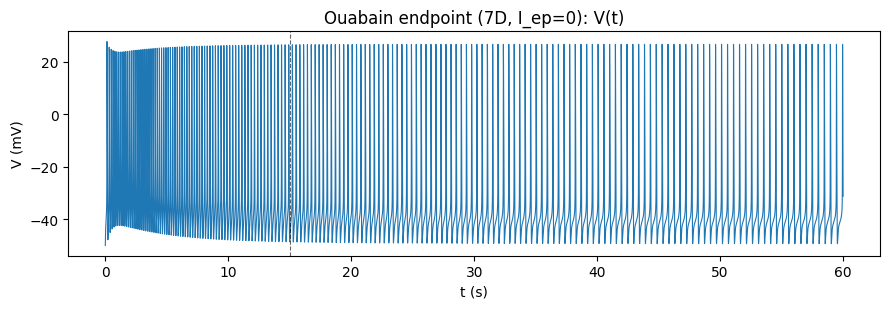

saved /Users/calvinlai/Desktop/MATH3888/outputs/figures/drug_endpoints/ouabain_V_trace.png
Ouabain 7D: PASS (regular_beating)


In [8]:
T_END_OUA = 60000.0
T_CUT_OUA = 15000.0

pars_oua = make_drug_pars(I_ep=0.0)
assert_pars_match_baseline_except(pars_oua, changed=('I_ep',))
assert pars_oua['I_ep'] == 0.0
assert np.isclose(pars_oua['g_I'], BASELINE_PARS['g_I'])

ode_oua, data_oua = run_7d('ouabain', pars_oua, T_END_OUA)
assert ode_oua.pars['I_ep'] == 0.0
met_oua = classify_endpoint(data_oua, T_CUT_OUA)
print(met_oua)
assert met_oua['regime'] != 'FAIL', met_oua

plot_V_trace(
    data_oua,
    title='Ouabain endpoint (7D, I_ep=0): V(t)',
    fname='ouabain_V_trace.png',
    t_cut=T_CUT_OUA,
)
summary_rows.append(metrics_row('ouabain', pars_oua['g_I'], pars_oua['I_ep'], met_oua))

if met_oua['regime'] != 'regular_beating':
    raise RuntimeError(
        'Ouabain endpoint did not match Hypothesis 2 (expected regular_beating). '
        f'Got regime={met_oua["regime"]}, detail={met_oua["detail"]}'
    )
print('Ouabain 7D: PASS (regular_beating)')


## 10. Combined TTX + ouabain — canonical 7D (`g_I = 0`, `I_ep = 0`)

Expected (Hypothesis 3): slow-wave suppressed → stable equilibrium. Use a longer run and late-window diagnostics.


Computing 7D ttx_ouabain: g_I=0.0, I_ep=0.0, T_END=120000.0 ms ...


  done: V in [-50, -25] mV


{'regime': 'equilibrium', 'detail': 'late V range=1.89e-07 mV, mean|dV/dt|=5.6e-12', 'V_min': -42.81221351792915, 'V_max': -42.81221332852681, 'period_s': nan, 'n_spikes': 0, 'spikes_per_cycle': nan, 'aps_absent': True, 'V_range_late': 1.8940234269848588e-07, 'mean_abs_dVdt': 5.59721915245547e-12}


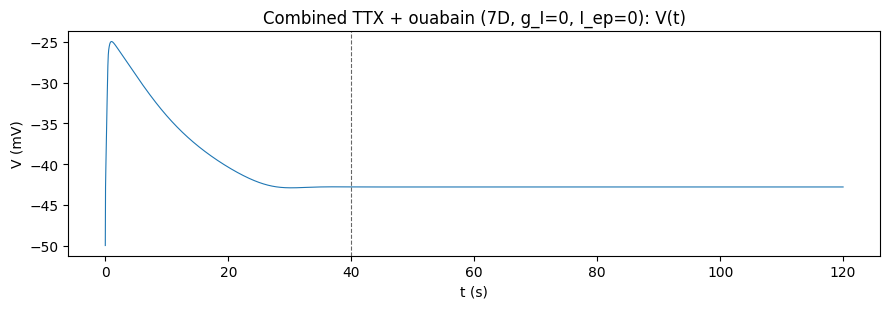

saved /Users/calvinlai/Desktop/MATH3888/outputs/figures/drug_endpoints/combined_V_trace.png
Combined TTX+ouabain 7D: PASS (equilibrium)


In [9]:
T_END_BOTH = 120000.0
T_CUT_BOTH = 40000.0
LATE_BOTH = 40000.0

pars_both = make_drug_pars(g_I=0.0, I_ep=0.0)
assert_pars_match_baseline_except(pars_both, changed=('g_I', 'I_ep'))
assert pars_both['g_I'] == 0.0 and pars_both['I_ep'] == 0.0

ode_both, data_both = run_7d('ttx_ouabain', pars_both, T_END_BOTH)
assert ode_both.pars['g_I'] == 0.0 and ode_both.pars['I_ep'] == 0.0
met_both = classify_endpoint(data_both, T_CUT_BOTH, late_window_ms=LATE_BOTH)
print(met_both)
assert met_both['regime'] != 'FAIL', met_both

plot_V_trace(
    data_both,
    title='Combined TTX + ouabain (7D, g_I=0, I_ep=0): V(t)',
    fname='combined_V_trace.png',
    t_cut=T_CUT_BOTH,
)
summary_rows.append(
    metrics_row('TTX+ouabain', pars_both['g_I'], pars_both['I_ep'], met_both)
)

if met_both['regime'] != 'equilibrium':
    raise RuntimeError(
        'Combined endpoint did not match Hypothesis 3 (expected equilibrium). '
        f'Got regime={met_both["regime"]}, detail={met_both["detail"]}'
    )
print('Combined TTX+ouabain 7D: PASS (equilibrium)')


## 11. Endpoint summary table


In [10]:
summary_path = FIGDIR / 'endpoint_summary.csv'
fieldnames = [
    'intervention', 'g_I', 'I_ep', 'regime', 'V_min', 'V_max',
    'period_s', 'n_spikes', 'spikes_per_cycle', 'aps_absent', 'detail',
]
with open(summary_path, 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(summary_rows)

print('intervention | g_I | I_ep | regime | V_min | V_max | period_s | n_spikes | spikes/cycle')
for row in summary_rows:
    print(
        f"{row['intervention']:12s} | {row['g_I']:4g} | {row['I_ep']:5g} | "
        f"{row['regime']:16s} | {row['V_min']:7.3f} | {row['V_max']:7.3f} | "
        f"{row['period_s']:8.3f} | {row['n_spikes']:8d} | {row['spikes_per_cycle']}"
    )
print('saved', summary_path)


intervention | g_I | I_ep | regime | V_min | V_max | period_s | n_spikes | spikes/cycle
untreated    |    4 | -0.22 | bursting         | -51.623 |  27.487 |    9.043 |       12 | 4.0
TTX          |    0 | -0.22 | slow_wave        | -52.463 | -38.896 |    9.971 |        0 | nan
ouabain      |    4 |     0 | regular_beating  | -49.296 |  26.607 |    0.449 |      105 | 1.0
TTX+ouabain  |    0 |     0 | equilibrium      | -42.812 | -42.812 |      nan |        0 | nan
saved /Users/calvinlai/Desktop/MATH3888/outputs/figures/drug_endpoints/endpoint_summary.csv


## 12. Overview figure and interpretation


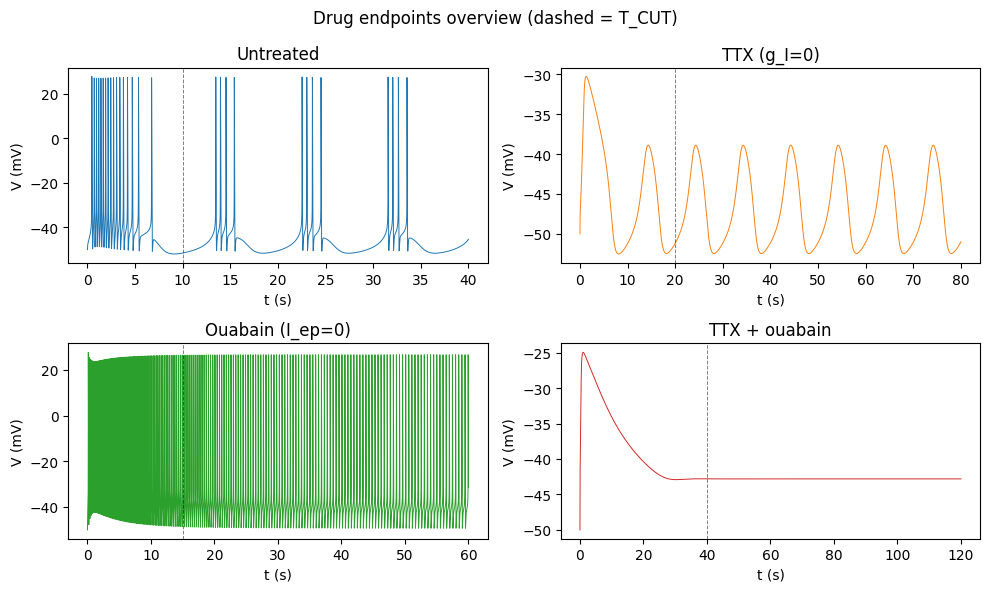

saved /Users/calvinlai/Desktop/MATH3888/outputs/figures/drug_endpoints/endpoint_overview.png

Interpretation (observational):
- Hypothesis 1 (TTX): slow_wave ; APs absent = True
- Hypothesis 2 (ouabain): regular_beating
- Hypothesis 3 (combined): equilibrium
- 7D vs 5D TTX max |error| across common states: 0.0020058555051249982


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=False)
panels = [
    (axes[0, 0], data_ref, T_CUT_REF, 'Untreated', 'C0'),
    (axes[0, 1], data_ttx, T_CUT_TTX, 'TTX (g_I=0)', 'C1'),
    (axes[1, 0], data_oua, T_CUT_OUA, 'Ouabain (I_ep=0)', 'C2'),
    (axes[1, 1], data_both, T_CUT_BOTH, 'TTX + ouabain', 'C3'),
]
for ax, data, t_cut, title, color in panels:
    ax.plot(data['t'] / 1000.0, data['V'], lw=0.7, color=color)
    ax.axvline(t_cut / 1000.0, color='k', ls='--', lw=0.7, alpha=0.5)
    ax.set_title(title)
    ax.set_xlabel('t (s)')
    ax.set_ylabel('V (mV)')
fig.suptitle('Drug endpoints overview (dashed = T_CUT)')
fig.tight_layout()
fig.savefig(FIGDIR / 'endpoint_overview.png', dpi=150)
plt.show()
print('saved', FIGDIR / 'endpoint_overview.png')

print('\nInterpretation (observational):')
print('- Hypothesis 1 (TTX):', met_ttx['regime'], '; APs absent =', met_ttx['aps_absent'])
print('- Hypothesis 2 (ouabain):', met_oua['regime'])
print('- Hypothesis 3 (combined):', met_both['regime'])
print('- 7D vs 5D TTX max |error| across common states:', max_abs_all)


## 13. Saved outputs / conclusion


In [12]:
saved = sorted(FIGDIR.glob('*'))
print('Files in', FIGDIR)
for p in saved:
    print(' -', p.name)

print('\nConclusion:')
print('Drug-endpoint validation (checklist 2.2–2.5) completed on the validated 7D model.')
print('Exact 5D TTX reduction agrees with 7D at g_I=0 within numerical tolerance.')
print('Checklist updates and git commits intentionally deferred.')


Files in /Users/calvinlai/Desktop/MATH3888/outputs/figures/drug_endpoints
 - combined_V_trace.png
 - endpoint_overview.png
 - endpoint_summary.csv
 - ouabain_V_trace.png
 - ttx_7d_vs_5d.png
 - ttx_7d_vs_5d_errors.csv
 - ttx_V_trace.png

Conclusion:
Drug-endpoint validation (checklist 2.2–2.5) completed on the validated 7D model.
Exact 5D TTX reduction agrees with 7D at g_I=0 within numerical tolerance.
Checklist updates and git commits intentionally deferred.
